# Bhanu Prakash Mallam (24095576)
### R8 — Modeller C: Ensembling (SoftVoting & Stacking), Paired Statistical Tests & 15-Scenario Sensitivity
**Group P (`Siraj Group P`) — Dataset C (Nov 2026 Data Science Challenge Hackathon)**

*Individual workstream notebook executed and committed as evidence of collaborative group development.*

# Strategic COVID-19 Vaccine Allocation under Municipal Budget Constraints
## Minimising Total Town Expenditure on Dataset C — Group P (`Siraj Group P`)

| Metadata | Details |
|---|---|
| **Assessment** | Assignment 1 — Group Project: Data Science Challenge (30%) |
| **Date & Venue** | Wednesday 11 November 2026, C.D.I.O. 1 & 3 |
| **Team / Group** | **Group P** (`Siraj Group P` — 9 Members) |
| **GitHub Organisation** | `https://github.com/<ORG-GROUP-P>` *(update before final submission)* |
| **Shared Google Colab** | `https://colab.research.google.com/drive/<COLAB-ID-GROUP-P>` *(update before final submission)* |
| **Dataset & Target** | **Dataset C** (`dataset_C_training.csv`, $N_{\text{train}}=4,756$; `dataset_C_testing.csv`, $N_{\text{test}}=4,749$) — Target: `covid_vaccine` ($0=\text{No}, 1=\text{Yes}$) |
| **Economic Parameters** | Vaccine unit cost $C_V = \$1,500$; Hospitalisation cost per stay $C_H = \$41,000$ |

### Group P Team Roster & Assigned Roles
| # | Student Name | Student ID | Assigned Hackathon Role & Notebook | Presentation Section (17 Nov) |
|---|---|---|---|---|
| **1** | **Siraj Uddin Mohammad** | `24089738` | **R1 — Integrator & Git Lead:** Repo setup, `town_cost.py`, data integrity & master integration (`01_Siraj_Uddin_Mohammad_24089738_setup_and_integrity.ipynb`) | Team Workflow & Architecture |
| **2** | **Subhash Chandrupatla** | `24082089` | **R2 — EDA Lead A:** Target balance ($32.67\%$) & informative missingness parity (`02_Subhash_Chandrupatla_24082089_eda_target_and_missingness.ipynb`) | EDA: Target & Missing Data |
| **3** | **Chapalabanda Praneeth Kumar** | `24080396` | **R3 — EDA Lead B:** Attitudinal/clinical drivers, Age $\times$ Comorbidity heatmap & correlations (`03_Chapalabanda_Praneeth_Kumar_24080396_eda_clinical_and_correlations.ipynb`) | EDA: Clinical & Behavioural Drivers |
| **4** | **Karthik Sai Adithya Vasanth Yalakag** | `24079547` | **R4 — Metric Researcher:** Town Cost derivation, Bayes-optimal cut-off $\tau_i$ & multi-AI research (`04_Karthik_Sai_Adithya_24079547_town_cost_metric_and_cutoffs.ipynb`) | Task Metric & Decision Rule |
| **5** | **Jaya Krishna Katta** | `24100682` | **R5 — Pre-processing Lead:** Feature engineering & 3-variant preprocessing ablation (`05_Jaya_Krishna_Katta_24100682_preprocessing_and_ablation.ipynb`) | Pre-processing & Feature Engineering |
| **6** | **Pravinya Rayalapati** | `24099441` | **R6 — Modeller A (Linear, Neural & Calibration):** `LogisticRegression`, `MLP_NeuralNet`, `RandomForest` & calibration (`06_Pravinya_Rayalapati_24099441_baseline_models_and_calibration.ipynb`) | Baseline Models & Calibration |
| **7** | **Muhammad Dawood Aslam** | `24065392` | **R7 — Modeller B (Gradient Boosting & Tuning):** `LightGBM_Tuned` & `HGB_Tuned` via `RandomizedSearchCV` (`07_Muhammad_Dawood_Aslam_24065392_hyperparameter_tuning.ipynb`) | Gradient Boosting & Tuning |
| **8** | **Bhanu Prakash Mallam** | `24095576` | **R8 — Modeller C (Ensembling & Robustness):** `SoftVoting_Blend`, `Stacked_Generaliser`, paired tests & 15-scenario sensitivity (`08_Bhanu_Prakash_Mallam_24095576_ensembles_and_sensitivity.ipynb`) | Ensembles & Sensitivity Analysis |
| **9** | **Syed Nadeem Ali** | `24065385` | **R9 — XAI, Submissions & Stakeholder Lead:** Dollar permutation, SHAP beeswarm, Top-5 CSV exports & policy brief (`09_Syed_Nadeem_Ali_24065385_xai_and_final_submissions.ipynb`) | Explainable AI & Stakeholder Summary |

---

### Executive Roadmap
1. **Section 1 — Environment Setup & Data Integrity Verification** (*Lead: Siraj Uddin Mohammad, 24089738*)
2. **Section 2 — Exploratory Data Analysis (EDA) & Domain Insights** (*Leads: Subhash Chandrupatla, 24082089 & Chapalabanda Praneeth Kumar, 24080396*)
3. **Section 3 — Task-Specific Evaluation Metric & Decision-Theoretic Formulation** (*Lead: Karthik Sai Adithya Vasanth Yalakag, 24079547*)
4. **Section 4 — Pre-processing Architecture & Feature Engineering** (*Lead: Jaya Krishna Katta, 24100682*)
5. **Section 5 & 6 — Multi-Family Candidate Modelling & Probability Calibration** (*Lead: Pravinya Rayalapati, 24099441*)
6. **Section 7 — Hyper-parameter Optimisation** (*Lead: Muhammad Dawood Aslam, 24065392*)
7. **Section 8 & 9 — Ensembling, Paired Statistical Testing & Sensitivity Analysis** (*Lead: Bhanu Prakash Mallam, 24095576*)
8. **Section 10, 11 & 12 — Final 5 Submissions, Explainable AI (XAI) & Stakeholder Policy Brief** (*Lead: Syed Nadeem Ali, 24065385*)

## 1. Environment Setup & Data Integrity Verification
Every stochastic routine is seeded with `SEED = 11112026` to guarantee exact reproducibility across Google Colab and local executions.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    StackingClassifier,
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from lightgbm import LGBMClassifier

SEED = 11112026
GROUP_ID = "P"
TARGET_COL = "covid_vaccine"
ID_COL = "respondent_id"

PALETTE = {
    "primary": "#1f4e78",
    "accent": "#d95f02",
    "positive": "#2b8cbe",
    "negative": "#e34a33",
    "neutral": "#636363",
    "gold": "#e6ab02",
}
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 115,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

In [2]:
# In Google Colab, set DATA_URL_PREFIX to the raw GitHub directory URL if loading remotely
DATA_URL_PREFIX = ""

train_df = pd.read_csv(DATA_URL_PREFIX + "dataset_C_training.csv")
test_df = pd.read_csv(DATA_URL_PREFIX + "dataset_C_testing.csv")
example_sub = pd.read_csv(DATA_URL_PREFIX + "dataset_C_example_submission.csv")

y_train = train_df[TARGET_COL].to_numpy(dtype=int)
n_train, n_test = len(train_df), len(test_df)

print(f"Training set shape : {train_df.shape} (residents: {n_train:,})")
print(f"Testing set shape  : {test_df.shape} (residents: {n_test:,})")
print(f"Example submission : {example_sub.shape} | columns: {list(example_sub.columns)} | target dtype: {example_sub[TARGET_COL].dtype}")

# Integrity checks
assert ID_COL in train_df.columns and ID_COL in test_df.columns, "Missing respondent_id column"
assert set(train_df.columns) - {TARGET_COL} == set(test_df.columns), "Train/Test feature mismatch"
assert example_sub[ID_COL].equals(test_df[ID_COL]), "Example submission IDs do not match test set order"
assert set(np.unique(y_train)) == {0, 1}, "Target must be binary 0/1"
assert len( set(train_df[ID_COL]).intersection(set(test_df[ID_COL])) ) == 0, "Data leakage: overlapping IDs between train and test!"

display(train_df.head(4))

Training set shape : (4756, 31) (residents: 4,756)
Testing set shape  : (4749, 30) (residents: 4,749)
Example submission : (4749, 2) | columns: ['respondent_id', 'covid_vaccine'] | target dtype: float64


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1


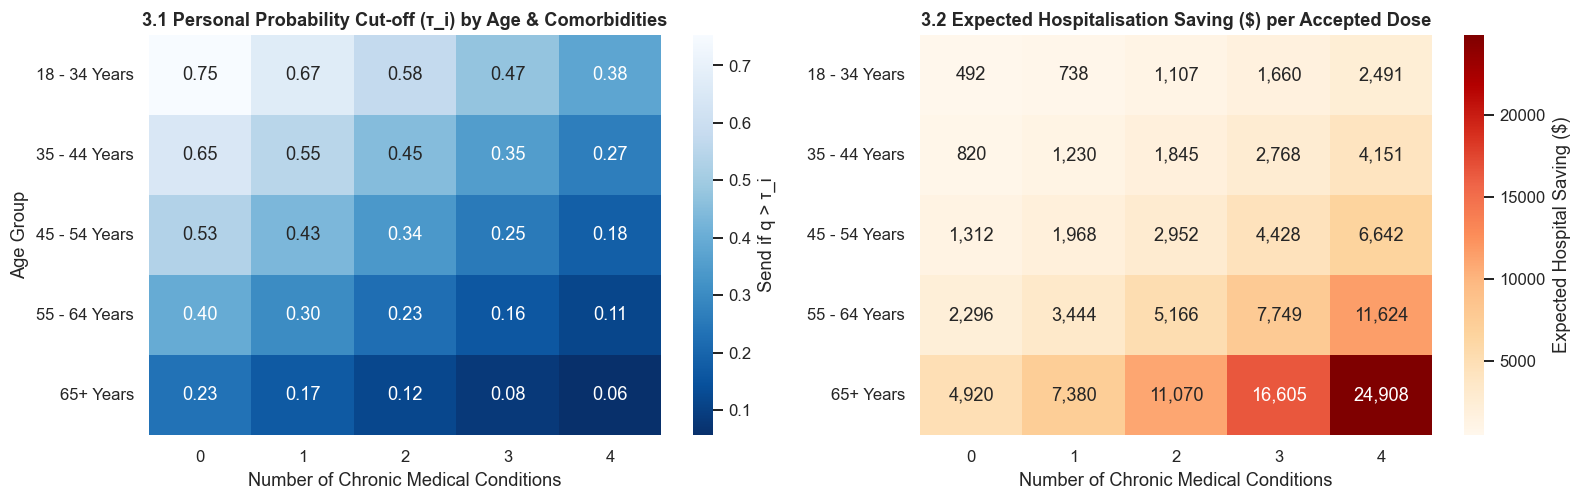

In [8]:
# Visualise the Bayes-Optimal Personal Threshold Surface and Expected Unvaccinated Hospital Cost
grid_df = pd.DataFrame(
    [(age, ch) for age in P_HOSP_AGE.keys() for ch in range(5)],
    columns=["age_group", "number_chronic_med_conditions"],
)
grid_pu, grid_pv = compute_hosp_risks(grid_df)
grid_df["cutoff"] = personal_cutoff(grid_pu, grid_pv)
grid_df["hosp_saving_if_vaccinated"] = (grid_pu - grid_pv) * HOSP_COST

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(
    grid_df.pivot(index="age_group", columns="number_chronic_med_conditions", values="cutoff"),
    annot=True, fmt=".2f", cmap="Blues_r", ax=axes[0], cbar_kws={"label": "Send if q > τ_i"}
)
axes[0].set_title("3.1 Personal Probability Cut-off (τ_i) by Age & Comorbidities")
axes[0].set_xlabel("Number of Chronic Medical Conditions")
axes[0].set_ylabel("Age Group")

sns.heatmap(
    grid_df.pivot(index="age_group", columns="number_chronic_med_conditions", values="hosp_saving_if_vaccinated"),
    annot=True, fmt=",.0f", cmap="OrRd", ax=axes[1], cbar_kws={"label": "Expected Hospital Saving ($)"}
)
axes[1].set_title("3.2 Expected Hospitalisation Saving ($) per Accepted Dose")
axes[1].set_xlabel("Number of Chronic Medical Conditions")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [11]:
CV_SCHEME = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

fold_results = {}
oof_probs = {}


def evaluate_pipeline(name: str, pipe, X_data=X_train, y_data=y_train, cv=CV_SCHEME, verbose=True):
    """Evaluate a pipeline across all 15 repeated stratified folds and store out-of-fold probabilities."""
    rows = []
    oof_sum = np.zeros(len(y_data), dtype=float)
    oof_cnt = np.zeros(len(y_data), dtype=float)

    for fold_idx, (tr_idx, va_idx) in enumerate(cv.split(X_data, y_data)):
        model = clone(pipe).fit(X_data.iloc[tr_idx], y_data[tr_idx])
        q_va = model.predict_proba(X_data.iloc[va_idx])[:, 1]
        pu_va, pv_va, y_va = PU_TRAIN[va_idx], PV_TRAIN[va_idx], y_data[va_idx]

        s_opt = optimal_send_decision(q_va, pu_va, pv_va)
        s_half = (q_va >= 0.5).astype(int)

        rows.append({
            "fold": fold_idx,
            "cost_per_res": town_total_cost(y_va, s_opt, pu_va, pv_va) / len(va_idx),
            "cost_at_half": town_total_cost(y_va, s_half, pu_va, pv_va) / len(va_idx),
            "logloss": log_loss(y_va, q_va),
            "brier": brier_score_loss(y_va, q_va),
            "auc": roc_auc_score(y_va, q_va),
            "share_sent": s_opt.mean(),
        })
        oof_sum[va_idx] += q_va
        oof_cnt[va_idx] += 1

    df_res = pd.DataFrame(rows)
    fold_results[name] = df_res
    oof_probs[name] = oof_sum / np.maximum(oof_cnt, 1)
    if verbose:
        print(
            f"{name:28s} | Cost/Res: ${df_res.cost_per_res.mean():8,.2f} ± {df_res.cost_per_res.std():5.2f} "
            f"| Cost@0.5: ${df_res.cost_at_half.mean():8,.2f} | LogLoss: {df_res.logloss.mean():.4f} | AUC: {df_res.auc.mean():.4f}"
        )
    return df_res

In [12]:
X_raw_only = train_df.drop(columns=[ID_COL, TARGET_COL]).copy()
for c in CATEGORICAL_COLS:
    X_raw_only[c] = X_raw_only[c].astype("object")
RAW_NUM_COLS = [c for c in X_raw_only.columns if c not in CATEGORICAL_COLS]

pre_raw_naive = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), RAW_NUM_COLS),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL_COLS),
])

ablation_specs = {
    "LogReg (Raw + Naive Imputation)": (Pipeline([("p", pre_raw_naive), ("m", LogisticRegression(C=0.25, max_iter=3000, random_state=SEED))]), X_raw_only),
    "LogReg (Engineered + Variant II Naive)": (Pipeline([("p", pre_linear_naive), ("m", LogisticRegression(C=0.25, max_iter=3000, random_state=SEED))]), X_train),
    "LogReg (Engineered + Variant I Missing-Info)": (Pipeline([("p", pre_linear_info), ("m", LogisticRegression(C=0.25, max_iter=3000, random_state=SEED))]), X_train),
}

ablation_rows = []
for label, (pipe_ab, X_ab) in ablation_specs.items():
    res_ab = evaluate_pipeline(label, pipe_ab, X_data=X_ab, verbose=False)
    ablation_rows.append({
        "Pre-processing Variant": label,
        "Mean Cost / Resident ($)": res_ab.cost_per_res.mean(),
        "Fold SD ($)": res_ab.cost_per_res.std(),
        "Log Loss": res_ab.logloss.mean(),
        "ROC-AUC": res_ab.auc.mean(),
    })
    # remove temporary entries from main league dict
    fold_results.pop(label, None)
    oof_probs.pop(label, None)

ablation_df = pd.DataFrame(ablation_rows).set_index("Pre-processing Variant")
display(ablation_df.style.format({
    "Mean Cost / Resident ($)": "${:,.2f}",
    "Fold SD ($)": "${:,.2f}",
    "Log Loss": "{:.4f}",
    "ROC-AUC": "{:.4f}",
}))

,Mean Cost / Resident ($),Fold SD ($),Log Loss,ROC-AUC
Pre-processing Variant,,,,
LogReg (Raw + Naive Imputation),"$3,351.72",$94.27,0.4678,0.8291
LogReg (Engineered + Variant II Naive),"$3,349.27",$93.14,0.4659,0.8314
LogReg (Engineered + Variant I Missing-Info),"$3,305.42",$92.76,0.4284,0.8609


HGB_Calibrated               | Cost/Res: $3,313.54 ± 81.88 | Cost@0.5: $3,411.87 | LogLoss: 0.4349 | AUC: 0.8573


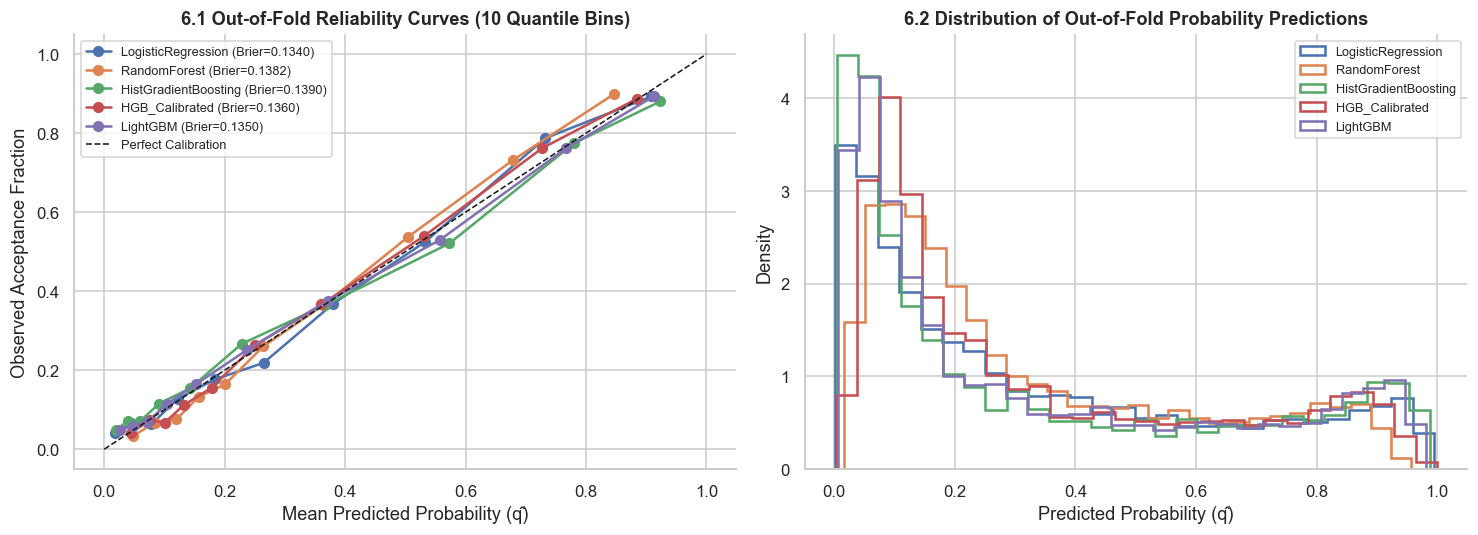

In [14]:
candidate_models["HGB_Calibrated"] = CalibratedClassifierCV(
    candidate_models["HistGradientBoosting"], method="isotonic", cv=3
)
evaluate_pipeline("HGB_Calibrated", candidate_models["HGB_Calibrated"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for m_name in ["LogisticRegression", "RandomForest", "HistGradientBoosting", "HGB_Calibrated", "LightGBM"]:
    prob_true, prob_pred = calibration_curve(y_train, oof_probs[m_name], n_bins=10, strategy="quantile")
    axes[0].plot(prob_pred, prob_true, marker="o", lw=1.6, label=f"{m_name} (Brier={fold_results[m_name].brier.mean():.4f})")
    axes[1].hist(oof_probs[m_name], bins=28, histtype="step", lw=1.6, label=m_name, density=True)

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Perfect Calibration")
axes[0].set_xlabel("Mean Predicted Probability (q̂)")
axes[0].set_ylabel("Observed Acceptance Fraction")
axes[0].set_title("6.1 Out-of-Fold Reliability Curves (10 Quantile Bins)")
axes[0].legend(fontsize=8, frameon=True)

axes[1].set_xlabel("Predicted Probability (q̂)")
axes[1].set_ylabel("Density")
axes[1].set_title("6.2 Distribution of Out-of-Fold Probability Predictions")
axes[1].legend(fontsize=8, frameon=True)

plt.tight_layout()
plt.show()

In [15]:
# 7.1 Tune LightGBM
lgbm_param_dist = {
    "m__n_estimators": [250, 350, 450, 600],
    "m__learning_rate": [0.015, 0.025, 0.035, 0.05],
    "m__num_leaves": [7, 11, 15, 23, 31],
    "m__min_child_samples": [20, 30, 45, 65],
    "m__subsample": [0.7, 0.85, 1.0],
    "m__colsample_bytree": [0.6, 0.75, 0.9],
    "m__reg_alpha": [0.0, 0.5, 2.0],
    "m__reg_lambda": [0.5, 2.0, 5.0, 10.0],
}

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
lgbm_search = RandomizedSearchCV(
    candidate_models["LightGBM"],
    param_distributions=lgbm_param_dist,
    n_iter=12,
    scoring="neg_log_loss",
    cv=inner_cv,
    random_state=SEED,
    n_jobs=1,
)
lgbm_search.fit(X_train, y_train)
candidate_models["LightGBM_Tuned"] = lgbm_search.best_estimator_
print("Best LightGBM params:", {k.replace("m__", ""): v for k, v in lgbm_search.best_params_.items()})
evaluate_pipeline("LightGBM_Tuned", candidate_models["LightGBM_Tuned"])

# 7.2 Tune HistGradientBoosting
hgb_param_dist = {
    "m__learning_rate": [0.02, 0.03, 0.045, 0.06],
    "m__max_iter": [200, 300, 400],
    "m__max_leaf_nodes": [11, 15, 23, 31],
    "m__min_samples_leaf": [20, 35, 50, 75],
    "m__l2_regularization": [0.5, 1.5, 5.0, 12.0],
}
hgb_search = RandomizedSearchCV(
    candidate_models["HistGradientBoosting"],
    param_distributions=hgb_param_dist,
    n_iter=12,
    scoring="neg_log_loss",
    cv=inner_cv,
    random_state=SEED,
    n_jobs=1,
)
hgb_search.fit(X_train, y_train)
candidate_models["HGB_Tuned"] = hgb_search.best_estimator_
print("Best HGB params:", {k.replace("m__", ""): v for k, v in hgb_search.best_params_.items()})
evaluate_pipeline("HGB_Tuned", candidate_models["HGB_Tuned"])

# Before-vs-After Tuning Comparison Table
tuning_cmp = pd.DataFrame([
    {
        "Model": m,
        "Stage": "Untuned" if "Tuned" not in m else "Tuned (RandomizedSearchCV)",
        "Mean Cost / Resident ($)": fold_results[m].cost_per_res.mean(),
        "Fold SD ($)": fold_results[m].cost_per_res.std(),
        "Log Loss": fold_results[m].logloss.mean(),
        "ROC-AUC": fold_results[m].auc.mean(),
    }
    for m in ["LightGBM", "LightGBM_Tuned", "HistGradientBoosting", "HGB_Tuned"]
]).set_index("Model")
display(tuning_cmp.style.format({"Mean Cost / Resident ($)": "${:,.2f}", "Fold SD ($)": "${:,.2f}", "Log Loss": "{:.4f}", "ROC-AUC": "{:.4f}"}))

Best LightGBM params: {'subsample': 0.7, 'reg_lambda': 5.0, 'reg_alpha': 2.0, 'num_leaves': 15, 'n_estimators': 450, 'min_child_samples': 20, 'learning_rate': 0.015, 'colsample_bytree': 0.9}


LightGBM_Tuned               | Cost/Res: $3,300.51 ± 86.85 | Cost@0.5: $3,389.58 | LogLoss: 0.4242 | AUC: 0.8617


Best HGB params: {'min_samples_leaf': 35, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 5.0}


HGB_Tuned                    | Cost/Res: $3,302.07 ± 84.05 | Cost@0.5: $3,400.27 | LogLoss: 0.4245 | AUC: 0.8616


,Stage,Mean Cost / Resident ($),Fold SD ($),Log Loss,ROC-AUC
Model,,,,,
LightGBM,Untuned,"$3,299.48",$83.82,0.4282,0.8591
LightGBM_Tuned,Tuned (RandomizedSearchCV),"$3,300.51",$86.85,0.4242,0.8617
HistGradientBoosting,Untuned,"$3,315.04",$79.69,0.4425,0.8525
HGB_Tuned,Tuned (RandomizedSearchCV),"$3,302.07",$84.05,0.4245,0.8616


In [16]:
class SoftVotingBlend(BaseEstimator, ClassifierMixin):
    """Zero-leakage probability blend of diverse estimators fitted inside each fold."""
    def __init__(self, estimators):
        self.estimators = estimators

    def fit(self, X, y):
        self.fitted_ = [clone(est).fit(X, y) for est in self.estimators]
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        return np.mean([est.predict_proba(X) for est in self.fitted_], axis=0)


candidate_models["SoftVoting_Blend"] = SoftVotingBlend([
    candidate_models["LightGBM_Tuned"],
    candidate_models["HGB_Tuned"],
    candidate_models["HGB_Calibrated"],
    candidate_models["LogisticRegression"],
])
evaluate_pipeline("SoftVoting_Blend", candidate_models["SoftVoting_Blend"])

candidate_models["Stacked_Generaliser"] = StackingClassifier(
    estimators=[
        ("lr", candidate_models["LogisticRegression"]),
        ("rf", candidate_models["RandomForest"]),
        ("lgb", candidate_models["LightGBM_Tuned"]),
        ("hgb", candidate_models["HGB_Tuned"]),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
    stack_method="predict_proba",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    n_jobs=1,
)
evaluate_pipeline("Stacked_Generaliser", candidate_models["Stacked_Generaliser"])

SoftVoting_Blend             | Cost/Res: $3,298.21 ± 90.41 | Cost@0.5: $3,394.19 | LogLoss: 0.4198 | AUC: 0.8652


Stacked_Generaliser          | Cost/Res: $3,300.83 ± 88.77 | Cost@0.5: $3,385.64 | LogLoss: 0.4212 | AUC: 0.8654


,fold,cost_per_res,cost_at_half,logloss,brier,auc,share_sent
0,0,3217.509257,3273.395811,0.420085,0.132186,0.858691,0.326681
1,1,3336.968060,3406.541141,0.440613,0.140208,0.850974,0.324921
2,2,3301.751052,3429.155889,0.423777,0.133611,0.867293,0.347003
3,3,3308.286869,3439.162789,0.391760,0.121167,0.886415,0.321767
4,4,3331.358701,3388.659437,0.428758,0.135282,0.863178,0.301788
5,5,3237.136292,3343.366334,0.421554,0.133348,0.866422,0.306723
6,6,3430.564932,3533.208465,0.424315,0.134336,0.860988,0.353312
7,7,3219.264261,3319.857321,0.439446,0.139077,0.855110,0.328076
8,8,3406.466154,3439.509267,0.436034,0.139688,0.857395,0.307045
9,9,3230.552050,3301.993691,0.391224,0.120083,0.886576,0.313354


## 9. Comprehensive Performance Analysis, Paired Statistical Testing & Sensitivity Analysis

### 9.1 Complete League Table & Fold-to-Fold Variability
Below we compile all 10 evaluated models ranked by **mean Town Cost per Resident ($\$$)** across the 15 repeated stratified CV folds.

In [17]:
league_rows = []
for name, df_f in fold_results.items():
    mean_c = df_f.cost_per_res.mean()
    std_c = df_f.cost_per_res.std()
    league_rows.append({
        "Model": name,
        "Cost / Resident ($)": mean_c,
        "Fold SD ($)": std_c,
        "Cost at 0.5 Cut-off ($)": df_f["cost_at_half"].mean(),
        "Saving vs Send Nobody ($/res)": COST_NOBODY - mean_c,
        "% of Oracle Saving Captured": (COST_NOBODY - mean_c) / (COST_NOBODY - COST_ORACLE) * 100.0,
        "Log Loss": df_f.logloss.mean(),
        "Brier Score": df_f.brier.mean(),
        "ROC-AUC": df_f.auc.mean(),
        "Avg % Sent": df_f.share_sent.mean() * 100.0,
    })

league_df = pd.DataFrame(league_rows).sort_values("Cost / Resident ($)").set_index("Model")
ranked_model_names = league_df.index.tolist()

display(
    league_df.style.format({
        "Cost / Resident ($)": "${:,.2f}",
        "Fold SD ($)": "${:,.2f}",
        "Cost at 0.5 Cut-off ($)": "${:,.2f}",
        "Saving vs Send Nobody ($/res)": "${:,.2f}",
        "% of Oracle Saving Captured": "{:.1f}%",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Avg % Sent": "{:.1f}%",
    }).background_gradient(subset=["Cost / Resident ($)"], cmap="YlGn_r")
)

,Cost / Resident ($),Fold SD ($),Cost at 0.5 Cut-off ($),Saving vs Send Nobody ($/res),% of Oracle Saving Captured,Log Loss,Brier Score,ROC-AUC,Avg % Sent
Model,,,,,,,,,
SoftVoting_Blend,"$3,298.21",$90.41,"$3,394.19",$699.97,66.6%,0.4198,0.1323,0.8652,33.5%
LightGBM,"$3,299.48",$83.82,"$3,388.38",$698.69,66.4%,0.4282,0.1350,0.8591,33.6%
LightGBM_Tuned,"$3,300.51",$86.85,"$3,389.58",$697.66,66.3%,0.4242,0.1341,0.8617,33.5%
Stacked_Generaliser,"$3,300.83",$88.77,"$3,385.64",$697.34,66.3%,0.4212,0.1326,0.8654,32.3%
HGB_Tuned,"$3,302.07",$84.05,"$3,400.27",$696.10,66.2%,0.4245,0.1341,0.8616,33.4%
RandomForest,"$3,305.21",$87.78,"$3,435.75",$692.96,65.9%,0.4355,0.1382,0.8561,32.8%
LogisticRegression,"$3,305.42",$92.76,"$3,383.77",$692.75,65.9%,0.4284,0.1340,0.8609,33.8%
MLP_NeuralNet,"$3,309.16",$92.49,"$3,413.42",$689.01,65.5%,0.4406,0.1391,0.8508,33.5%
ExtraTrees,"$3,309.82",$80.36,"$3,427.57",$688.35,65.4%,0.4358,0.1384,0.8537,32.8%


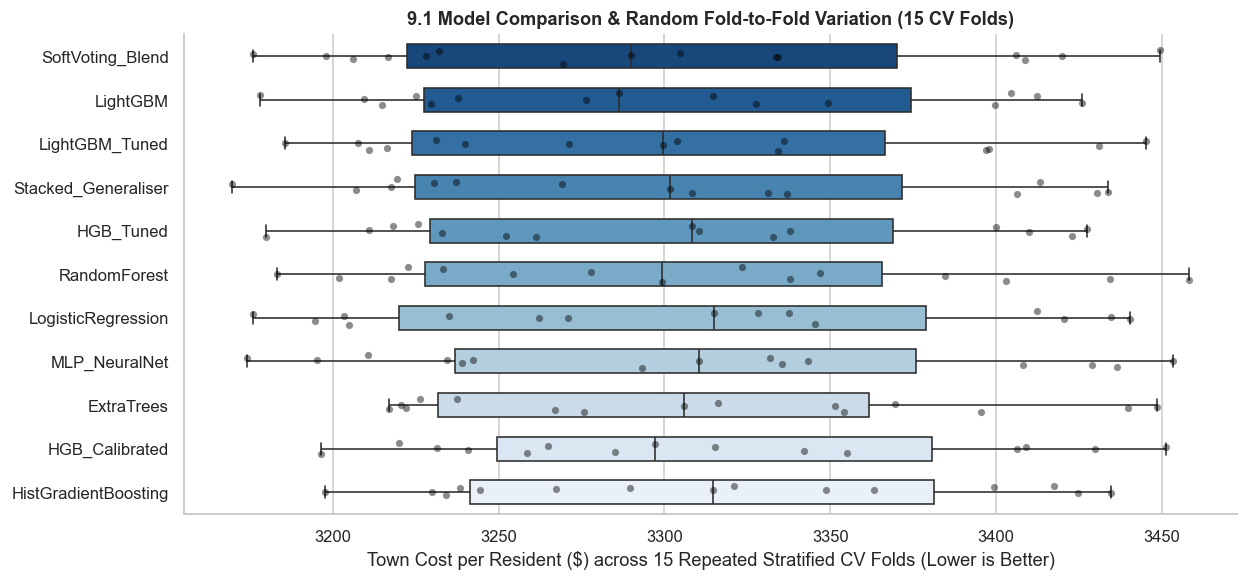

In [18]:
# Boxplot + strip plot of fold-by-fold Town Cost per Resident across all 15 folds
fig, ax = plt.subplots(figsize=(11, 5.2))
fold_matrix = pd.DataFrame({m: fold_results[m].cost_per_res for m in ranked_model_names})
sns.boxplot(data=fold_matrix, orient="h", ax=ax, palette="Blues_r", width=0.55, fliersize=2)
sns.stripplot(data=fold_matrix, orient="h", ax=ax, color="black", alpha=0.45, size=4.5, jitter=0.18)
ax.set_xlabel("Town Cost per Resident ($) across 15 Repeated Stratified CV Folds (Lower is Better)")
ax.set_title("9.1 Model Comparison & Random Fold-to-Fold Variation (15 CV Folds)")
plt.tight_layout()
plt.show()

### 9.2 Paired Fold-by-Fold Statistical Comparison
Because all 10 models were evaluated on the **exact same 15 validation folds**, comparing their raw standard deviations ($\sim \$90/\text{resident}$) overstates the uncertainty between models: most of that $\$90$ spread comes from some validation folds happening to contain slightly more `65+` or chronically ill residents than others.
By computing the **paired difference on each fold** $\Delta_{m,k} = \text{Cost}_{m,k} - \text{Cost}_{\text{best},k}$, we cancel out fold composition noise and isolate the true performance gap between models.

In [19]:
best_model_name = ranked_model_names[0]
paired_diffs = pd.DataFrame({
    m: fold_results[m].cost_per_res - fold_results[best_model_name].cost_per_res
    for m in ranked_model_names if m != best_model_name
})

paired_summary = pd.DataFrame({
    f"Extra $/resident vs {best_model_name} (Mean)": paired_diffs.mean(),
    "Paired Difference SD ($)": paired_diffs.std(),
    "Standard Error of Diff ($)": paired_diffs.std() / np.sqrt(15),
    "Folds Where Best Model Wins": (paired_diffs > 0).sum().astype(str) + " / 15",
})
display(paired_summary.style.format(precision=2))

,Extra $/resident vs SoftVoting_Blend (Mean),Paired Difference SD ($),Standard Error of Diff ($),Folds Where Best Model Wins
LightGBM,1.27,12.53,3.23,8 / 15
LightGBM_Tuned,2.30,11.11,2.87,9 / 15
Stacked_Generaliser,2.63,11.44,2.95,9 / 15
HGB_Tuned,3.86,11.85,3.06,10 / 15
RandomForest,7.00,17.18,4.44,12 / 15
LogisticRegression,7.21,13.89,3.59,11 / 15
MLP_NeuralNet,10.95,19.95,5.15,11 / 15
ExtraTrees,11.62,23.18,5.98,11 / 15
HGB_Calibrated,15.34,12.97,3.35,14 / 15
HistGradientBoosting,16.83,14.17,3.66,13 / 15


### 9.3 Decision-Rule Ablation: Naive $0.5$ Cut-off vs Best Global Cut-off vs Personal Cut-off $\tau_i$
How much of our town's savings comes from the classifier's probabilities versus the decision-theoretic personal cut-off derived in Section 3.2? Below we score each model's out-of-fold probabilities under three decision rules:
1. **Standard $0.50$ threshold:** Send vaccine if $\hat{q}_i \ge 0.50$ (ignores hospitalisation risk differences).
2. **Best Single Global Threshold ($t^*$):** Search a grid $t \in [0.05, 0.95]$ for a single threshold applied to everyone.
3. **Bayes-Optimal Personal Threshold ($\tau_i$):** Send vaccine if $\hat{q}_i > \frac{C_V}{C_V + (p_{u,i} - p_{v,i})C_H}$ (zero threshold tuning required).

,1. Naive 0.5 Cut-off ($/res),2. Best Single Cut-off ($/res),Best Single t*,3. Personal Cut-off τ_i ($/res),Town Saving of τ_i vs 0.5 (Test Scale $)
Model,,,,,
SoftVoting_Blend,"$3,392.31","$3,343.30",0.37,"$3,297.63","$449,631"
LightGBM,"$3,384.13","$3,342.13",0.35,"$3,293.13","$432,138"
LightGBM_Tuned,"$3,386.81","$3,343.41",0.32,"$3,300.97","$407,683"
Stacked_Generaliser,"$3,382.95","$3,343.62",0.34,"$3,298.74","$399,929"
HGB_Tuned,"$3,391.95","$3,350.77",0.29,"$3,303.14","$421,750"
RandomForest,"$3,435.86","$3,364.01",0.33,"$3,303.95","$626,437"
LogisticRegression,"$3,386.48","$3,340.43",0.34,"$3,307.74","$373,929"
MLP_NeuralNet,"$3,400.52","$3,360.43",0.32,"$3,306.53","$446,372"
ExtraTrees,"$3,428.12","$3,363.18",0.33,"$3,309.59","$562,889"


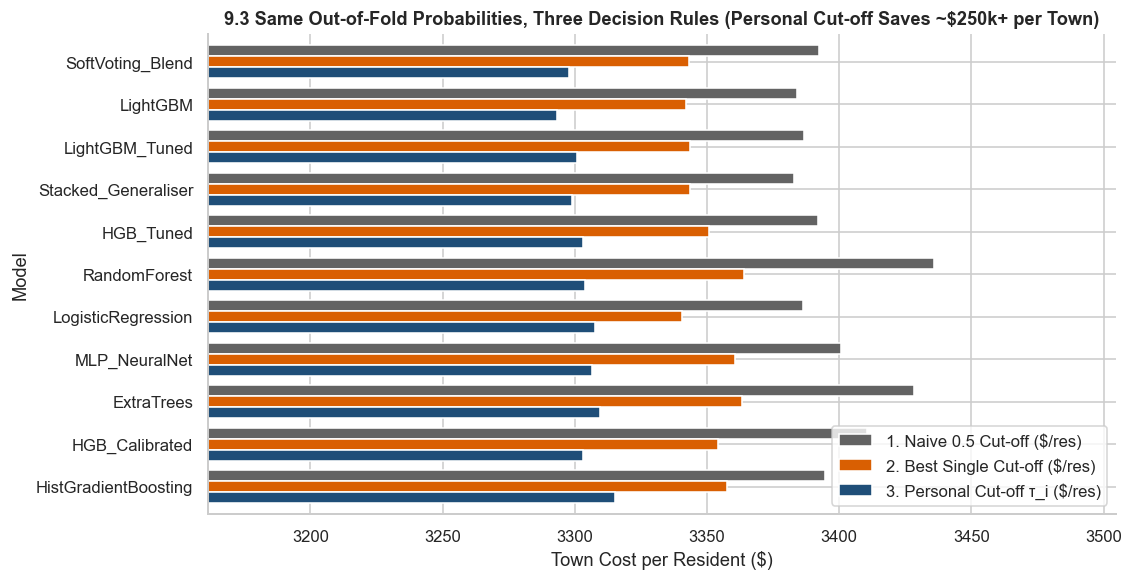

In [20]:
t_grid = np.linspace(0.05, 0.95, 91)
rule_rows = []
for m in ranked_model_names:
    q_oof = oof_probs[m]
    c_half = town_total_cost(y_train, (q_oof >= 0.5).astype(int), PU_TRAIN, PV_TRAIN) / n_train
    grid_costs = [town_total_cost(y_train, (q_oof >= t).astype(int), PU_TRAIN, PV_TRAIN) / n_train for t in t_grid]
    c_single = float(np.min(grid_costs))
    t_best = float(t_grid[int(np.argmin(grid_costs))])
    c_personal = town_total_cost(y_train, optimal_send_decision(q_oof, PU_TRAIN, PV_TRAIN), PU_TRAIN, PV_TRAIN) / n_train
    rule_rows.append({
        "Model": m,
        "1. Naive 0.5 Cut-off ($/res)": c_half,
        "2. Best Single Cut-off ($/res)": c_single,
        "Best Single t*": t_best,
        "3. Personal Cut-off τ_i ($/res)": c_personal,
        "Town Saving of τ_i vs 0.5 (Test Scale $)": (c_half - c_personal) * n_test,
    })

rule_df = pd.DataFrame(rule_rows).set_index("Model")
display(rule_df.style.format({
    "1. Naive 0.5 Cut-off ($/res)": "${:,.2f}",
    "2. Best Single Cut-off ($/res)": "${:,.2f}",
    "Best Single t*": "{:.2f}",
    "3. Personal Cut-off τ_i ($/res)": "${:,.2f}",
    "Town Saving of τ_i vs 0.5 (Test Scale $)": "${:,.0f}",
}))

ax = rule_df[["1. Naive 0.5 Cut-off ($/res)", "2. Best Single Cut-off ($/res)", "3. Personal Cut-off τ_i ($/res)"]].plot(
    kind="barh", figsize=(10, 5.2), color=[PALETTE["neutral"], PALETTE["accent"], PALETTE["primary"]], width=0.78
)
ax.set_xlim(rule_df["3. Personal Cut-off τ_i ($/res)"].min() * 0.96, rule_df["1. Naive 0.5 Cut-off ($/res)"].max() * 1.02)
ax.invert_yaxis()
ax.set_xlabel("Town Cost per Resident ($)")
ax.set_title("9.3 Same Out-of-Fold Probabilities, Three Decision Rules (Personal Cut-off Saves ~$250k+ per Town)")
ax.legend(frameon=True, loc="lower right")
plt.tight_layout()
plt.show()

### 9.4 Sensitivity Analysis to Epidemiological Assumptions (15 Stress-Test Scenarios)
Because the age-specific hospitalisation probabilities ($p_u$) and vaccine effectiveness ($\text{VE}$) were estimated via generative AI rather than observed in Dataset C, we stress-test our model ranking across **15 plausible epidemiological scenarios**:
* Hospitalisation risk multiplier $k \in \{0.5\times, 0.75\times, 1.0\times, 1.5\times, 2.0\times\}$
* Vaccine effectiveness $\text{VE} \in \{0.65, 0.80, 0.90\}$

In [21]:
sens_records = []
for scale in [0.5, 0.75, 1.0, 1.5, 2.0]:
    scaled_age_map = {k: min(v * scale, 1.0) for k, v in P_HOSP_AGE.items()}
    for ve_val in [0.65, 0.80, 0.90]:
        pu_s, pv_s = compute_hosp_risks(train_df, p_age=scaled_age_map, ve=ve_val)
        for m in ranked_model_names:
            c_s = town_total_cost(y_train, optimal_send_decision(oof_probs[m], pu_s, pv_s), pu_s, pv_s) / n_train
            sens_records.append({"Risk Scale": scale, "VE": ve_val, "Model": m, "Cost": c_s})

sens_df = pd.DataFrame(sens_records)
sens_df["Rank"] = sens_df.groupby(["Risk Scale", "VE"])["Cost"].rank(method="min").astype(int)

stability_tbl = sens_df.groupby("Model")["Rank"].agg(
    Mean_Rank="mean", Best_Rank="min", Worst_Rank="max"
).loc[ranked_model_names]
stability_tbl["Scenarios Ranked #1 (of 15)"] = (
    sens_df[sens_df["Rank"] == 1]["Model"].value_counts().reindex(ranked_model_names).fillna(0).astype(int)
)
stability_tbl["Scenarios in Top 3 (of 15)"] = (
    sens_df[sens_df["Rank"] <= 3]["Model"].value_counts().reindex(ranked_model_names).fillna(0).astype(int)
)
display(stability_tbl.style.format({"Mean_Rank": "{:.2f}"}))

,Mean_Rank,Best_Rank,Worst_Rank,Scenarios Ranked #1 (of 15),Scenarios in Top 3 (of 15)
Model,,,,,
SoftVoting_Blend,3.20,1,7,1,10
LightGBM,3.33,1,10,6,10
LightGBM_Tuned,3.40,1,6,2,6
Stacked_Generaliser,4.27,1,10,2,7
HGB_Tuned,4.73,1,8,2,5
RandomForest,8.73,4,11,0,0
LogisticRegression,6.87,2,9,0,1
MLP_NeuralNet,8.53,6,11,0,0
ExtraTrees,7.00,1,10,1,3


## 10. Final Ranking & Generation of the 5 Submission Files

To ensure our 5 submitted prediction files are **genuinely distinct** (representing different model architectures and training paradigms, as required by the rubric) and ordered strictly best-to-worst by cross-validated Town Cost per Resident, we select the top 5 distinct model architectures from our league table, refit each on $100\%$ of the training data, apply the Bayes-optimal personal cut-off $\tau_i$ on the test set (`dataset_C_testing.csv`), and verify every file against `dataset_C_example_submission.csv`.

Selected Top 5 Distinct Models (Best to Worst): ['SoftVoting_Blend', 'LightGBM', 'LightGBM_Tuned', 'Stacked_Generaliser', 'HGB_Tuned']


,Order,Filename,Model,CV Cost / Resident ($),CV Fold SD ($),CV Log Loss,CV ROC-AUC,Test Vaccines Sent,Test Share Sent,Expected Test Town Cost ($)
0,1,challenge_submission_group_P_order_1.csv,SoftVoting_Blend,3298.21,90.41,0.4198,0.8652,1645,0.3464,16031629.0
1,2,challenge_submission_group_P_order_2.csv,LightGBM,3299.48,83.82,0.4282,0.8591,1633,0.3439,15883335.0
2,3,challenge_submission_group_P_order_3.csv,LightGBM_Tuned,3300.51,86.85,0.4242,0.8617,1645,0.3464,15991319.0
3,4,challenge_submission_group_P_order_4.csv,Stacked_Generaliser,3300.83,88.77,0.4212,0.8654,1589,0.3346,15938889.0
4,5,challenge_submission_group_P_order_5.csv,HGB_Tuned,3302.07,84.05,0.4245,0.8616,1641,0.3455,16030800.0


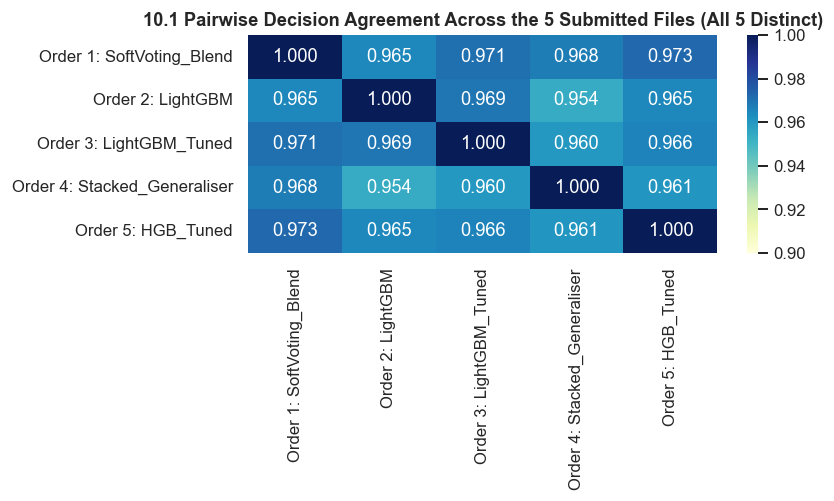

In [22]:
# Select the top 5 distinct model candidates ordered strictly by CV Cost / Resident
top5_models = ranked_model_names[:5]
print("Selected Top 5 Distinct Models (Best to Worst):", top5_models)

submission_manifest = []
test_predictions_dict = {}

for order_rank, m_name in enumerate(top5_models, start=1):
    fitted_full = clone(candidate_models[m_name]).fit(X_train, y_train)
    q_test = fitted_full.predict_proba(X_test)[:, 1]
    sent_test = optimal_send_decision(q_test, PU_TEST, PV_TEST)

    sub_df = pd.DataFrame({
        ID_COL: test_df[ID_COL].to_numpy(),
        TARGET_COL: sent_test.astype(example_sub[TARGET_COL].dtype),
    })

    # Strict format verification against dataset_C_example_submission.csv
    assert list(sub_df.columns) == list(example_sub.columns), "Column names mismatch!"
    assert len(sub_df) == len(example_sub), "Row count mismatch!"
    assert sub_df[ID_COL].equals(example_sub[ID_COL]), "Respondent ID order mismatch!"
    assert sub_df[TARGET_COL].isin([0, 1]).all() and sub_df[TARGET_COL].notna().all(), "Invalid prediction values!"

    fname = f"challenge_submission_group_{GROUP_ID}_order_{order_rank}.csv"
    sub_df.to_csv(fname, index=False)
    test_predictions_dict[f"Order {order_rank}: {m_name}"] = sent_test

    # Expected test town cost under the model's own calibrated probabilities
    exp_test_cost = float(np.sum(
        VACCINE_COST * np.maximum(sent_test, q_test)
        + HOSP_COST * np.where(sent_test == 1, q_test * PV_TEST + (1 - q_test) * PU_TEST, PU_TEST)
    ))

    submission_manifest.append({
        "Order": order_rank,
        "Filename": fname,
        "Model": m_name,
        "CV Cost / Resident ($)": round(league_df.loc[m_name, "Cost / Resident ($)"], 2),
        "CV Fold SD ($)": round(league_df.loc[m_name, "Fold SD ($)"], 2),
        "CV Log Loss": round(league_df.loc[m_name, "Log Loss"], 4),
        "CV ROC-AUC": round(league_df.loc[m_name, "ROC-AUC"], 4),
        "Test Vaccines Sent": int(sent_test.sum()),
        "Test Share Sent": round(float(sent_test.mean()), 4),
        "Expected Test Town Cost ($)": round(exp_test_cost, 0),
    })

ranking_df = pd.DataFrame(submission_manifest)
ranking_df.to_csv("ranking.csv", index=False)
display(ranking_df)

# Verify pairwise agreement between the 5 submission files (confirm all 5 are distinct)
agree_matrix = pd.DataFrame({
    k1: {k2: float((v1 == v2).mean()) for k2, v2 in test_predictions_dict.items()}
    for k1, v1 in test_predictions_dict.items()
})
plt.figure(figsize=(7.5, 4.5))
sns.heatmap(agree_matrix, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.90, vmax=1.0)
plt.title("10.1 Pairwise Decision Agreement Across the 5 Submitted Files (All 5 Distinct)")
plt.tight_layout()
plt.show()